In [1]:
import os
os.environ.pop("DEBUG", None)
from pathlib import Path

import sys
sys.path.append(str(Path.cwd().parent))

from datetime import datetime
import shutil
from hydromt_sfincs import SfincsModel, utils
from hydromt._utils import log
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from python.twl_boundary import create_twl_boundary

c:\Users\adrie\anaconda3\envs\hydromt-sfincs\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# root folder
PROJECT_FOLDER = Path.cwd().parent
MODEL_FOLDER = Path.cwd().parent / 'model'
yml_path = PROJECT_FOLDER / 'data_catalog.yml'
DATA_FOLDER = PROJECT_FOLDER / 'data'


In [3]:
# input
model_root = MODEL_FOLDER / "jakarta_base"
region = DATA_FOLDER/ 'geojson/jkt_bay_1.geojson'
use_subgrid = False


In [4]:
if Path(model_root).exists():
    shutil.rmtree(model_root)

# Initialize logging, the lower the log level number, the more verbose (more info) the output
# NOTSET=0-9, DEBUG=10, INFO=20, WARNING=30, ERROR=40, CRITICAL=50
log.initialize_logging()
log.set_log_level(log_level=20)

# Add file handler to log to a file
log_file = Path(model_root) / "hydromt_sfincs.log"
logger = log._add_filehandler(log_file)

# catalog_path = os.path.join(os.getcwd(),'catalog')
# yaml_path = os.path.join(catalog_path,'data_catalog.yml')
# data_catalog = hydromt.DataCatalog(data_libs=[yaml_path])

# Initialize SfincsModel Python class with the artifact data catalog which contains publically available data for North Italy
sf = SfincsModel(
    data_libs=yml_path,  # specify which data libraries to use
    root=model_root,  # specify the root directory for the model
    mode="w+",  # specify the mode for opening the model (r=read only, r+=append, w=write, w+=overwrite
    write_gis=True,  # specify whether to write GIS data
)

2026-11-27 09:19:21,408 - hydromt.data_catalog.data_catalog - data_catalog - INFO - Parsing data catalog from f:\BTP Work\2026\ews-pantura\data_catalog.yml
2026-11-27 09:19:21,901 - hydromt.model.model - model - INFO - Initializing sfincs model from hydromt_sfincs (v2.0.0rc1).
2026-11-27 09:19:21,903 - hydromt.model.model - model - WARNING - No region component found in components.


In [5]:
sf.grid.create_from_region(
    region={"geom": region},  # specify the region geometry
    res=100,  # specify the resolution
    rotated=True,  # specify whether the grid is rotated
    crs="utm",  # specify the coordinate reference system, when "utm", the UTM zone is automatically detected
)


2026-11-27 09:19:23,119 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading jkt_bay_1.geojson GeoDataFrame data from f:\BTP Work\2026\ews-pantura\data\geojson\jkt_bay_1.geojson
2026-11-27 09:19:23,235 - hydromt.hydromt_sfincs.components.config.config - config - INFO - Updating 9 attributes in model config.


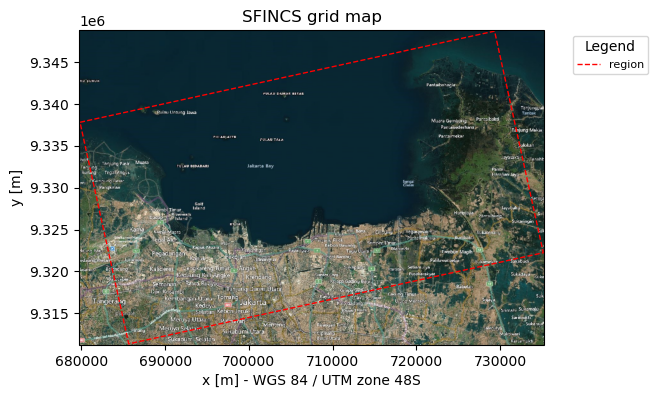

In [6]:
# show the model grid outline
_ = sf.plot_basemap(
    variable="grid",
    plot_region=True,
    bmap="sat",
    zoomlevel=12,
    grid_kwargs={"linewidth": 0.3},
)

2026-11-27 09:19:30,502 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading deltadtm RasterDataset data from f:\TUD_CEG_Repository\MSc_Thesis\Data\DeltaDTM v1.1\Asia\deltadtm_v1_1.vrt


2026-11-27 09:19:34,140 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading gebco RasterDataset data from f:\TUD_CEG_Repository\MSc_Thesis\Data\gebco\gebco.vrt
2026-11-27 09:19:38,146 - hydromt.hydromt_sfincs.components.grid.elevation - elevation - WARNING - Interpolate elevation at 6 cells


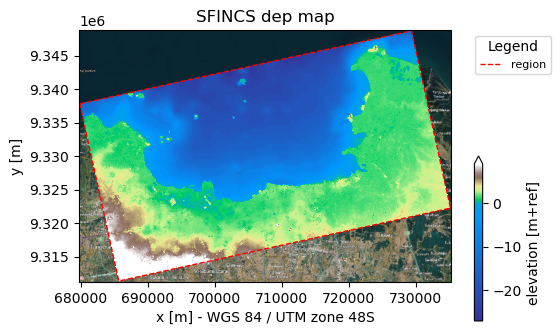

In [7]:
# In this example we want to combine 2 elevation datasets, merit_hydro as elevation and gebco as bathymetry, in that order.
# NOTE: from the 1st dataset (merit_hydro) only elevation above ("zmin":0.001) meters is used;
# the 2nd elevation dataset (gebco) is used where the 1st dataset returned nodata values
# elevation_list = [{"elevation": "merit_hydro", "zmin": 0.001}, {"elevation": "gebco"}]
elevation_list = [{"elevation": "deltadtm", "zmin": 0.001},{"elevation": "gebco"}]

# Add depth information to modelgrid based on these chosen datasets
sf.elevation.create(elevation_list=elevation_list, buffer_cells=1)

# Make a plot of the merged topobathy, here colour limits are set between an elevation of -5 to 5 meters
_ = sf.plot_basemap(variable="dep", plot_region=True, bmap="sat", zoomlevel=12)

2026-11-27 09:19:44,978 - hydromt.data_catalog.data_catalog - data_catalog - WARNING - overwriting data source 'jkt_bay_1.geojson' with provider user and version _UNSPECIFIED_.
2026-11-27 09:19:44,981 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading jkt_bay_1.geojson GeoDataFrame data from f:\BTP Work\2026\ews-pantura\data\geojson\jkt_bay_1.geojson
2026-11-27 09:19:45,075 - hydromt.hydromt_sfincs.components.grid.mask - mask - INFO - 0 gaps outside valid elevation range < 10.0 km2.


2026-11-27 09:19:45,167 - hydromt.hydromt_sfincs.components.config.config - config - INFO - Updating 2 attributes in model config.


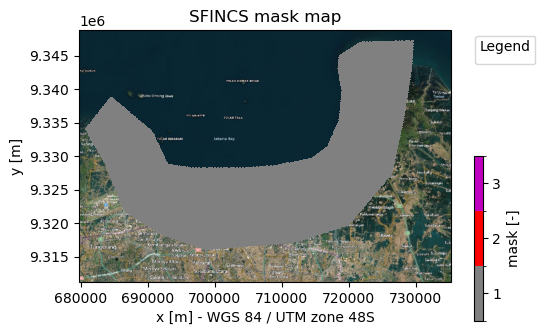

In [8]:
# Defining your active cells can be based on multiple criteria, here we only specify a minimum elevation of -5 meters,
# meaning all cells above -5 are considered to be active. Check-out the method documentation for more options.
# sf.mask.create_active(zmin=-5,drop_area=100)
sf.mask.create_active(include_polygon=region)

# # Make a plot of the mask file
_ = sf.plot_basemap(
    variable="mask", plot_region=False, plot_bounds=True, bmap="sat", zoomlevel=12
)

2026-11-27 09:19:51,381 - hydromt.model.components.grid - grid - WARNING - Replacing grid map: mask


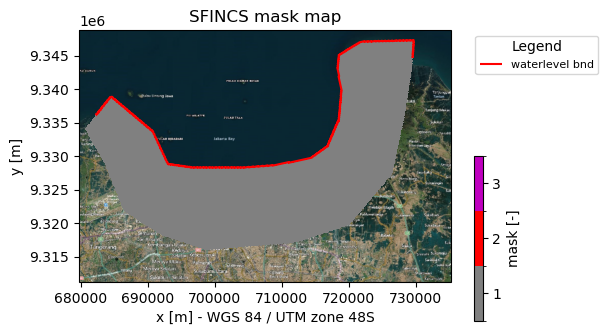

In [9]:
# Here we add water level cells along the coastal boundary, for cells up to an elevation of -5 meters
sf.mask.create_boundary(
    btype="waterlevel",
    zmax=-1,
    reset_bounds=True,
)

_ = sf.plot_basemap(
    variable="mask", plot_region=False, plot_bounds=True, bmap="sat", zoomlevel=12
)

2026-11-27 09:19:58,255 - hydromt.hydromt_sfincs.components.grid.roughness - roughness - INFO - Set other manning options to None in config that are unused in SFINCS in case of specifying manningfile (manning, manning_land, manning_sea, rgh_lev_land).


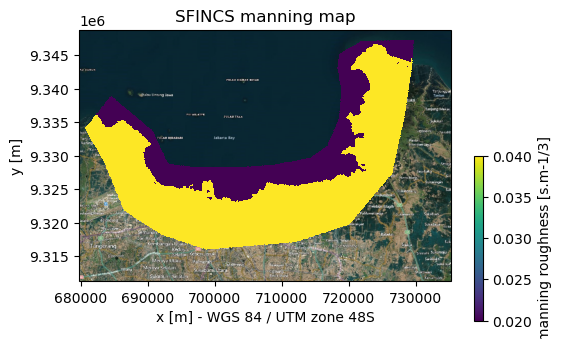

In [10]:
# Some reclass tables are available in the hydromt_sfincs DATADIR
# e.g. vito_mapping.csv for vito_2015 landuse classification
# data_dir = r'f:\TUD_CEG_Repository\MSc_Thesis\Data'
# reclass_table = os.path.join(data_dir, "vito_mapping.csv")

# # use the river manning raster in combination with vito_2015 land to derive the manning roughness file
# roughness_list = [{"lulc": "vito_2020", "reclass_table": reclass_table}]

sf.roughness.create(
    # roughness_list=roughness_list,
    manning_land=0.04,
    manning_sea=0.02,
    rgh_lev_land=0,  # the minimum elevation of the land
)
_ = sf.plot_basemap(variable="manning", plot_bounds=False, bmap="sat", zoomlevel=12)

In [11]:
if use_subgrid:
    # Repeat elevation and roughness sets for clarity
    elevation_list = [{"elevation": "deltadtm", "zmin": 0.001}, {"elevation": "gebco"}]

    # Roughness sets
    # roughness_list = [{"lulc": "vito_2020", "reclass_table": reclass_table}]

    sf.subgrid.create(
        elevation_list=elevation_list,
        # roughness_list=roughness_list,
        nr_subgrid_pixels=10,
        write_dep_tif=True,
        write_man_tif=True,
    )

    # NOTE: we turned on that the merged topobathy of the different (high-res) datasets is written to a geotiff

    # uncomment to see the subgrid table variales
    # sf.subgrid.data

    # we can plot the 2D subgrid variables
    _ = sf.plot_basemap(
        variable=sf.subgrid.data["u_navg"], plot_bounds=False, bmap="sat", zoomlevel=12
    )

(<Figure size 600x428.571 with 2 Axes>,
 <GeoAxes: title={'center': 'SFINCS dep map'}, xlabel='x [m] - WGS 84 / UTM zone 48S', ylabel='y [m]'>)

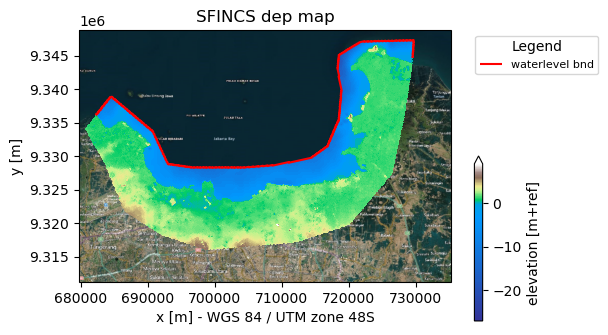

In [12]:
# plot basemap, in this case boundary points should be added (and plotted because of plot_geoms=True)
sf.plot_basemap(
    variable="dep", plot_geoms=True, plot_bounds=True, bmap="sat", zoomlevel=12
)

(<Figure size 600x428.571 with 2 Axes>,
 <GeoAxes: title={'center': 'SFINCS dep map'}, xlabel='x [m] - WGS 84 / UTM zone 48S', ylabel='y [m]'>)

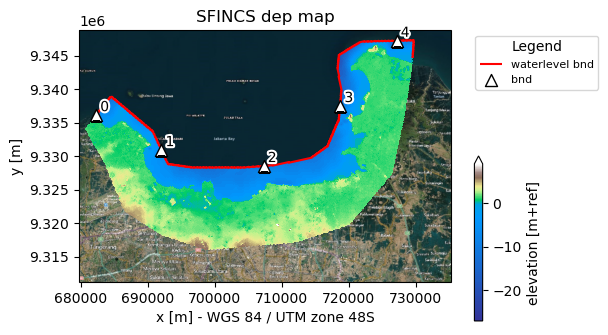

In [13]:
sf.water_level.create_boundary_points_from_mask(bnd_dist=20000.0)
sf.plot_basemap(
    variable="dep", plot_geoms=True, plot_bounds=True, bmap="sat", zoomlevel=12
)

In [14]:
sf.write()

2026-11-27 09:20:17,914 - hydromt.hydromt_sfincs.components.grid.subgrid - subgrid - INFO - No subgrid table available to write.


Querying TWL database.....
Interpolate TWL data to boundary point.....
Querying Surge database.....
Interpolate surge data to boundary point.....
Extracting time series.....
Resampling data.....
Extreme value analysis for boundary 0
Threshold = 0.89 m
Number of peaks = 211
Number of event per year Ns = 2.81
RMSE GPD = 0.003
Extreme value analysis for boundary 1
Threshold = 0.896 m
Number of peaks = 217
Number of event per year Ns = 2.89
RMSE GPD = 0.003
Extreme value analysis for boundary 2
Threshold = 0.894 m
Number of peaks = 222
Number of event per year Ns = 2.96
RMSE GPD = 0.003
Extreme value analysis for boundary 3
Threshold = 0.88 m
Number of peaks = 224
Number of event per year Ns = 2.99
RMSE GPD = 0.003
Extreme value analysis for boundary 4
Threshold = 0.871 m
Number of peaks = 221
Number of event per year Ns = 2.95
RMSE GPD = 0.003
Saving bzs file.....


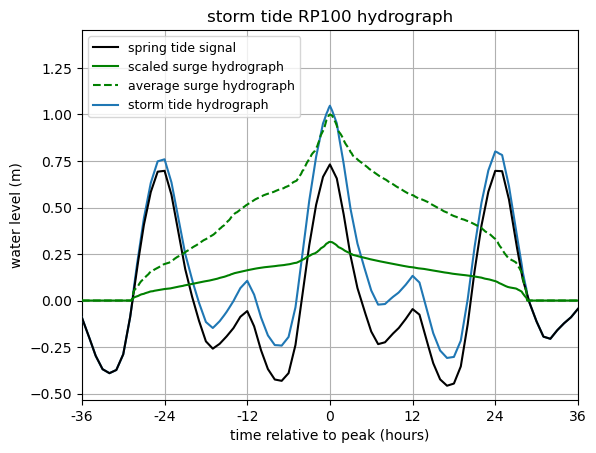

In [18]:
# read from bnd create to gstm
bnd_point = sf.water_level.gdf.to_crs(4326)
xy = np.column_stack([bnd_point.geometry.x, bnd_point.geometry.y])
# bzs_files = create_twl_boundary(xy,RP=1000, k=3)

bzs_files, bzs = create_twl_boundary(xy,RP=100,
                        k=1,dt=600,nhour=36,
                        percentile = 0.999,
                        tide_type = 'spring',
                        make_plot=True)

In [ ]:
sf.write()

In [ ]:
src = r"f:\TUD_CEG_Repository\MSc_Thesis\Code\run.bat"
dst = Path(model_root) / 'run.bat'

if not dst.exists():
    shutil.copy(src, dst)

run_path = model_root
cur_dir = os.getcwd()

os.chdir(run_path)
os.system("run.bat")
os.chdir(cur_dir)

In [ ]:
# catalog_path = os.path.join(os.getcwd(),'catalog')
# yaml_path = os.path.join(catalog_path,'data_catalog.yml')

mod = SfincsModel(model_root, mode="r")
mod = SfincsModel(model_root, data_libs=[yaml_path], mode="r")
mod.output.read()
list(mod.output.data.keys())

In [ ]:
# plot the model layout
fig, ax = mod.plot_basemap(fn_out=None, bmap="sat", figsize=(11, 7))

In [ ]:
# read global surface water occurance (GSWO) data to mask permanent water
gswo = mod.data_catalog.get_rasterdataset("gswo", geom=mod.region, buffer=10)


hmin = 0.05  # minimum flood depth [m] to plot

if Path(model_root+'/subgrid').exists():
    # first we are going to select our highest-resolution elevation dataset
    depfile = os.path.join(model_root, "subgrid", "dep_subgrid.tif")
    da_dep = mod.data_catalog.get_rasterdataset(depfile)
    
    # secondly we are reading in the model results
    da_zsmax = mod.output.data["zsmax"].max(dim="timemax")

    # Fourthly, we downscale the floodmap
    da_hmax = utils.downscale_floodmap(
        zsmax=da_zsmax,
        dep=da_dep,
        hmin=hmin,
        # gdf_mask=gdf,
        # floodmap_fn=os.path.join(model_root, "floodmap.tif") # uncomment to save to <mod.root>/floodmap.tif
    )
    gswo_mask = gswo.raster.reproject_like(da_dep, method="max") <= 5

    da_hmax = da_hmax.where(gswo_mask).where(da_hmax > hmin)

else:
    # permanent water where water occurence > 5%
    gswo_mask = gswo.raster.reproject_like(mod.grid.data, method="max") <= 5

    # hmax is computed by SFINCS and read-in from the sfincs_map.nc file
    da_hmax = mod.output.data["hmax"].max(dim="timemax")

    # get overland flood depth with GSWO and set minimum flood depth
    da_hmax = da_hmax.where(gswo_mask).where(da_hmax > hmin)

# update attributes for colorbar label later
da_hmax.attrs.update(long_name="flood depth", unit="m")

In [ ]:
# create hmax plot and save to mod.root/figs/hmax.png
fig, ax = mod.plot_basemap(
    fn_out=None,
    figsize=(8, 6),
    variable=da_hmax,
    plot_bounds=False,
    plot_geoms=False,
    bmap="sat",
    zoomlevel=12,
    vmin=0,
    vmax=2.0,
    cmap=plt.cm.viridis,
    cbar_kwargs={"shrink": 0.6, "anchor": (0, 0)},
)
ax.set_title(f"SFINCS maximum water depth")
# plt.savefig(join(mod.root, 'figs', 'hmax.png'), dpi=225, bbox_inches="tight")

In [ ]:
log.logging.shutdown()

In [ ]:
sf.elevation.data['dep']

In [ ]:
import rasterio
from rasterio.plot import show
dep_tif = r'f:\TUD_CEG_Repository\MSc_Thesis\Code\trial\trial_semarang\gis\dep.tif'
dep_file = r'f:\TUD_CEG_Repository\MSc_Thesis\Code\trial\trial_semarang\sfincs.dep'
with rasterio.open(dep_tif) as src:
    data = src.read(1)  # read first band
    plt.imshow(data, cmap="viridis")
    plt.colorbar(label="Value")
    plt.title("Raster Band 1")
    plt.show()
    # show(src)

In [ ]:
import rioxarray
import matplotlib.pyplot as plt

ds = rioxarray.open_rasterio(dep_tif)

ds.plot()
plt.show()

In [ ]:
import numpy as np

mmax = 286   # from sfincs.inp
nmax = 213   # from sfincs.inp

dep = np.fromfile(dep_file, dtype="float32")
dep
# dep = dep.reshape((nmax, mmax))

In [ ]:
40879/213